# # Image denoiser with Autoencoders

In [39]:
from keras.datasets import mnist
import numpy as np
from keras.models import Sequential
from keras.layers import Dense, Conv2D, Conv2DTranspose
import matplotlib.pyplot as plt

In [40]:
(input_train, target_train), (input_test, target_test) = mnist.load_data()
input_train.shape, target_train.shape, input_test.shape, target_test.shape

((60000, 28, 28), (60000,), (10000, 28, 28), (10000,))

In [41]:
img_width = input_train.shape[1]
img_height = input_train.shape[2]
img_channels = 1

In [42]:
input_train = input_train.reshape(input_train.shape[0], img_width, img_height, img_channels)
input_test = input_test.reshape(input_test.shape[0], img_width, img_height, img_channels)
input_train.shape, input_test.shape

((60000, 28, 28, 1), (10000, 28, 28, 1))

In [43]:
# Normalization
input_train = input_train.astype('float32') / 255
input_test = input_test.astype('float32') / 255

In [44]:
# input_train[0]

In [45]:
epochs = 7
batch_size = 64
noise_factor = 0.9

In [46]:
# Add noise
pure_train = input_train
noise_train = np.random.normal(0, 1, pure_train.shape)
noisy_train = pure_train + noise_train * noise_factor
# noisy_train = np.clip(noisy_train, 0, 1)

pure_test = input_test
noise_test = np.random.normal(0, 1, pure_test.shape)
noisy_test = pure_test + noise_test * noise_factor


In [47]:
# Visualization
images_to_visualize = 10
samples = noisy_train[:images_to_visualize]

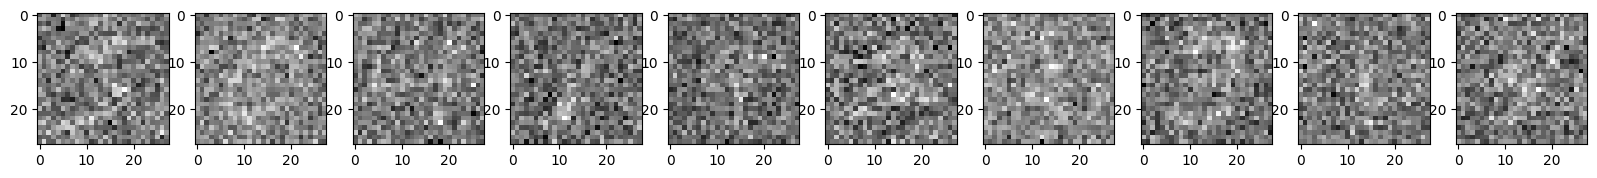

In [48]:
plt.figure(figsize=(20, 4))
for i in range(images_to_visualize):
    plt.subplot(2, images_to_visualize, i+1)
    plt.gray()
    plt.imshow(samples[i].reshape(28, 28))

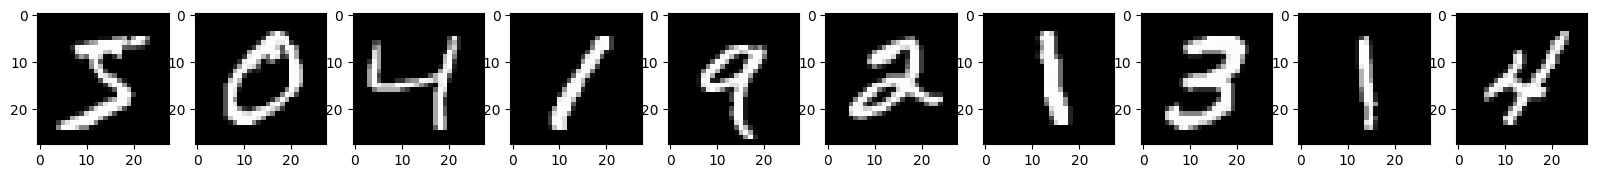

In [49]:
plt.figure(figsize=(20, 4))
for i in range(images_to_visualize):
    plt.subplot(2, images_to_visualize, i+1)
    plt.gray()
    plt.imshow(pure_train[i].reshape(28, 28))

In [50]:
# Modeling
model = Sequential()

# Encoder
model.add(Conv2D(64, (5, 5), activation='relu', input_shape=(img_width, img_height, img_channels)))
model.add(Conv2D(16, (3, 3), activation='relu'))
model.add(Conv2D(4, (3, 3), activation='relu'))

# Code
model.add(Conv2D(2, (3, 3), activation='relu'))

# Decode
model.add(Conv2DTranspose(4, (3, 3), activation='relu'))
model.add(Conv2DTranspose(16, (3, 3), activation='relu'))
model.add(Conv2DTranspose(64, (5, 5), activation='relu'))

model.add(Conv2DTranspose(1, (3, 3), activation='sigmoid'))



In [51]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_8 (Conv2D)               │ (None, 24, 24, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 22, 22, 16)     │         9,232 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 20, 20, 4)      │           580 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 18, 18, 2)      │            74 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_8              │ (None, 20, 20, 4)      │            76 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_9              │ (None, 22, 22, 16)     │           592 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_10             │ (None, 26, 26, 64)     │        25,664 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_11             │ (None, 28, 28, 1)      │           577 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,459 (150.23 KB)

 Trainable params: 38,459 (150.23 KB)

 Non-trainable params: 0 (0.00 B)

In [52]:
# Compile
model.compile(optimizer='adam', loss='binary_crossentropy')

In [53]:
history = model.fit(noisy_train,
                    pure_train,
                    epochs=epochs,
                    batch_size=batch_size,
                    validation_split=0.2,
                    verbose=True)

Epoch 1/7
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 11ms/step - loss: 0.1839 - val_loss: 0.1509
Epoch 2/7
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.1481 - val_loss: 0.1471
Epoch 3/7
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 0.1452 - val_loss: 0.1450
Epoch 4/7
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.1435 - val_loss: 0.1437
Epoch 5/7
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.1424 - val_loss: 0.1425
Epoch 6/7
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.1415 - val_loss: 0.1428
Epoch 7/7
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.1407 - val_loss: 0.1412


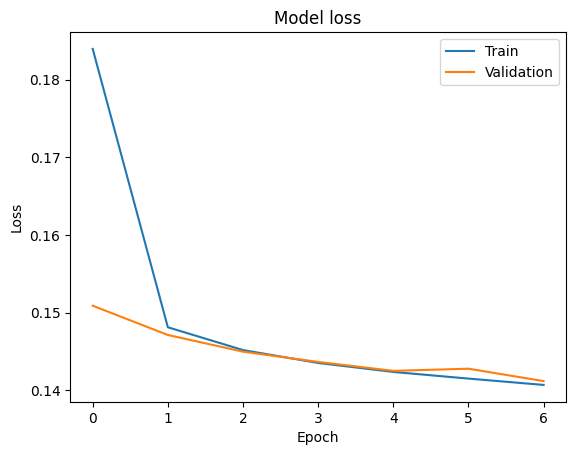

In [54]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper right')

In [55]:
images_to_visualize = 7
samples = noisy_test[:images_to_visualize]
targets = target_test[:images_to_visualize]

In [56]:
denoised_images = model.predict(samples)
denoised_images.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 571ms/step


(7, 28, 28, 1)

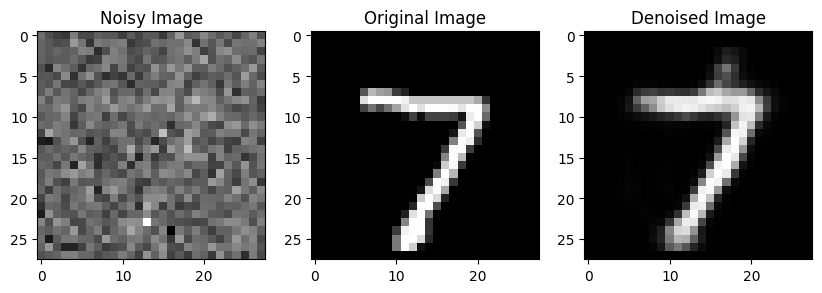

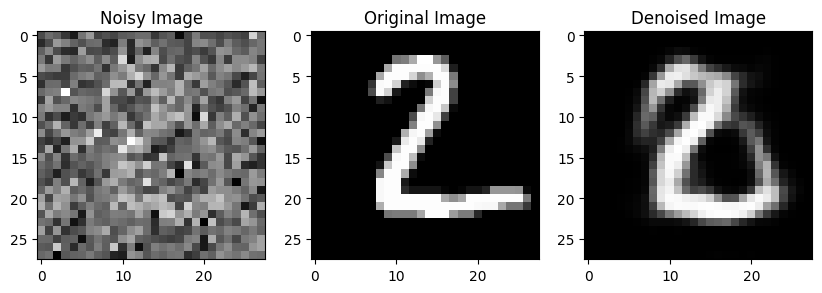

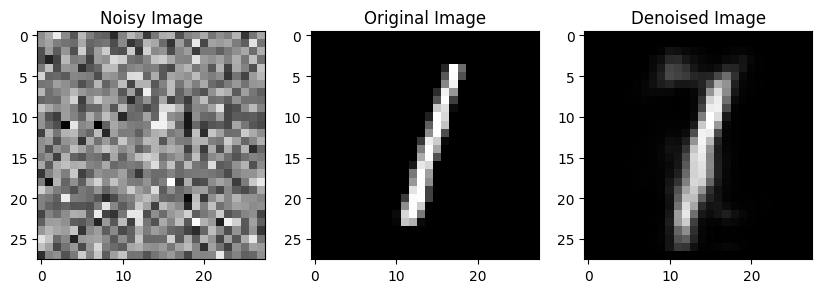

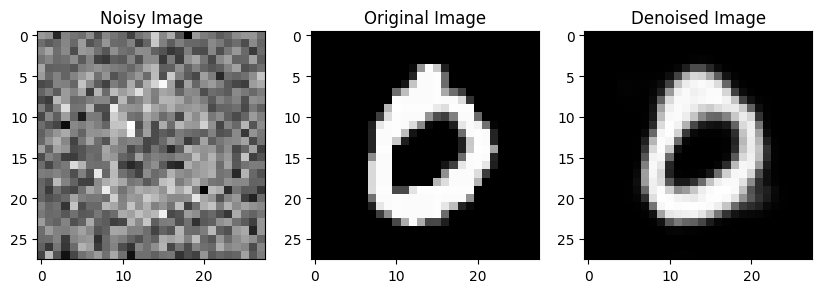

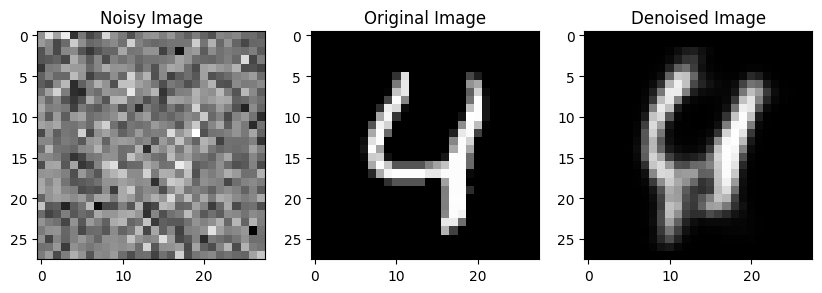

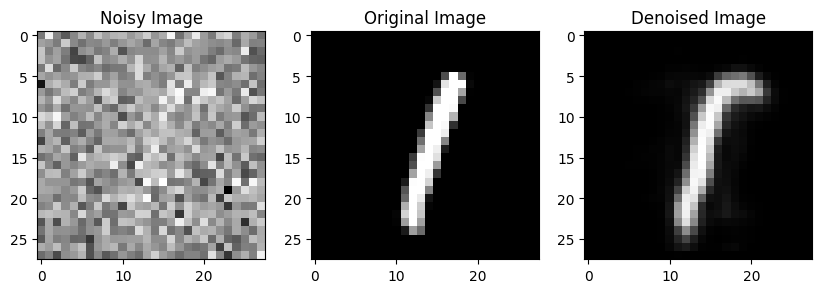

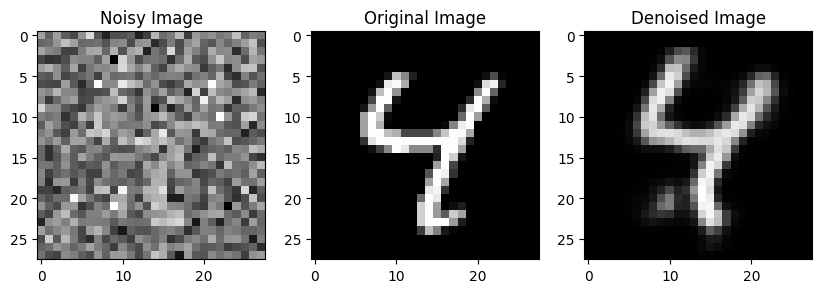

In [57]:
for i in range(images_to_visualize):
    image_with_noise = samples[i][:, :, 0]
    pure_image = input_test[i][:, :, 0]
    denoised_image = denoised_images[i][:, :, 0]
    input_class = targets[i]

    fig, axes = plt.subplots(1, 3)
    fig.set_size_inches(10, 4)

    axes[0].imshow(image_with_noise, cmap='gray')
    axes[0].set_title('Noisy Image')

    axes[1].imshow(pure_image, cmap='gray')
    axes[1].set_title('Original Image')

    axes[2].imshow(denoised_image, cmap='gray')
    axes[2].set_title('Denoised Image')

    plt.show()